# Monthly go-live reports

After a hospital starts using the AAA model, someone has to keep checking that it still behaves as it did in testing. This notebook sets that routine up in four steps:

1. **Create monthly files.** Real monthly data does not exist yet, so we *simulate* months from the practice hospitals. Each month is written in the same folder layout a real hospital would drop in every month (`features`, `predictions`, `embeddings`, and `labels` when confirmed answers exist).
2. **Learn "normal" once** from the reference hospital the model was validated on, and save it.
3. **Run `monitor.py` on every month.** One traffic-light report per month (HTML), plus a history file.
4. **Look at the trend**: a month-by-month dashboard, an index page you can hand to a committee, a JSON summary, and a small script (`run_monthly.py`) for real use.

Three simulation scenarios show what the reports look like when things go wrong:

| Scenario | What happens | What the reports should show |
|---|---|---|
| `stable` | Every month is a random sample of the same hospital | all green |
| `drift` | From a chosen month, the patient/scanner mix slowly changes (e.g. older patients, arterial phase) | case-mix alerts turning yellow, then red |
| `no_answer` | From a chosen month, the model starts returning blanks | the no-answer alert turning yellow, then red |

`monitor.py` must be in the same folder.

In [1]:
import json, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import HTML, display

import monitor

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

## CONFIG

In [2]:
# ------------------------------------------------------------------------------------------
HOSPITAL_NAME  = "demo_hospital"      # name shown in the reports
REFERENCE_NAME = "hospital_a"         # the hospital the model was validated on
REFERENCE_DIR  = Path("../../dataset/practice/hospital_a")

# ---- simulation settings (ignore these if you already have real monthly folders) ----
SCENARIO        = "drift"             # "stable" | "drift" | "no_answer"
SOURCE_DIR      = Path("../../dataset/practice/hospital_a")   # cases that look like the validation hospital
DRIFT_DIR       = Path("../../dataset/practice/hospital_d")   # what the hospital drifts towards (scenario "drift")
N_MONTHS        = 6
CASES_PER_MONTH = 60
START_MONTH     = "2026-12"
CHANGE_STARTS_IN_MONTH = 3            # month number (1 = first) when drift / blanks begin
LABELS_EVERY_N_MONTHS  = 1            # 1 = confirmed answers every month; 2 = only every second month, etc.
SEED = 0

MONTHLY_ROOT = Path("monthly_data")   # real data goes in monthly_data/<hospital>/<YYYY-MM>/
OUT_DIR      = Path("monitoring")     # reports, history and the saved reference profile
SIMULATE     = True                   # False = skip step 1 and use the folders that already exist
RESET        = True                   # True = delete old simulated months and old history first
# ------------------------------------------------------------------------------------------
TABLES = ["features", "labels", "predictions", "embeddings"]

## 1. Create monthly files

Folder layout (this is also what a real hospital should drop in each month):

```
monthly_data/
  <hospital>/
    2026-12/   features.parquet  predictions.parquet  embeddings.parquet  [labels.parquet]
    2027-01/   ...
```
`labels.parquet` is optional, because confirmed answers (a radiologist's review) usually arrive later than the scans. Without it, the report simply skips the accuracy checks.

In [3]:
def read_tables(folder):
    return {t: pd.read_parquet(Path(folder) / f"{t}.parquet") for t in TABLES}

def wide(tabs):
    df = tabs["features"]
    for t in ["labels", "predictions", "embeddings"]:
        df = df.merge(tabs[t], on="case_id")
    return df

def month_name(i):
    return str(pd.Period(START_MONTH, "M") + i)

def draw(pool, n, rng):
    n = min(n, len(pool))                      # never sample the same scan twice inside one month
    return pool.iloc[rng.choice(len(pool), n, replace=False)]

def change_level(m):
    """0 before the change starts, then grows with each month."""
    k = m + 1 - CHANGE_STARTS_IN_MONTH + 1
    return 0 if k <= 0 else k

if SIMULATE:
    rng = np.random.default_rng(SEED)
    src_tabs = read_tables(SOURCE_DIR)
    cols = {t: list(src_tabs[t].columns) for t in TABLES}
    pool_src = wide(src_tabs)
    pool_drift = wide(read_tables(DRIFT_DIR)) if SCENARIO == "drift" else None
    target = MONTHLY_ROOT / HOSPITAL_NAME
    if RESET and target.exists(): shutil.rmtree(target)
    plan = []
    for m in range(N_MONTHS):
        k = change_level(m)
        if SCENARIO == "drift":
            alpha = min(1.0, k / (N_MONTHS - CHANGE_STARTS_IN_MONTH + 1)) if k else 0.0
            n_drift = int(round(alpha * CASES_PER_MONTH))
            df = pd.concat([draw(pool_src, CASES_PER_MONTH - n_drift, rng), draw(pool_drift, n_drift, rng)], ignore_index=True) if n_drift else draw(pool_src, CASES_PER_MONTH, rng).reset_index(drop=True)
            note = f"{alpha:.0%} of scans from {DRIFT_DIR.name}"
        else:
            df = draw(pool_src, CASES_PER_MONTH, rng).reset_index(drop=True)
            note = "random sample of the source hospital"
            if SCENARIO == "no_answer" and k:
                rate = min(0.5, 0.04 * k)
                blank = rng.random(len(df)) < rate
                df["pred_aaa"] = df["pred_aaa"].astype(object); df.loc[blank, "pred_aaa"] = None
                df.loc[blank, "pred_max_diameter_mm"] = np.nan
                note = f"{rate:.0%} of model answers blanked"
        folder = target / month_name(m); folder.mkdir(parents=True, exist_ok=True)
        with_labels = (m % LABELS_EVERY_N_MONTHS == 0)
        for t in TABLES:
            if t == "labels" and not with_labels: continue
            df[[c for c in cols[t] if c in df.columns]].to_parquet(folder / f"{t}.parquet", index=False)
        plan.append({"month": month_name(m), "scans": len(df), "labels_included": with_labels, "what_changed": note})
    print(f"scenario '{SCENARIO}' written to {target}")
    display(pd.DataFrame(plan))
else:
    print("SIMULATE = False: using the folders already in", MONTHLY_ROOT / HOSPITAL_NAME)

scenario 'drift' written to monthly_data/demo_hospital


,month,scans,labels_included,what_changed
0,2026-12,60,True,0% of scans from hospital_d
1,2027-01,60,True,0% of scans from hospital_d
2,2027-02,60,True,25% of scans from hospital_d
3,2027-03,60,True,50% of scans from hospital_d
4,2027-04,60,True,75% of scans from hospital_d
5,2027-05,60,True,100% of scans from hospital_d


## 2. Learn "normal" once and save it

The reference profile stores what the validated hospital looks like: its mix of scanners, phases, ages, its brightness and diameter distribution, and a map of what its scans look like (from the embeddings). Every monthly batch is compared with this profile. Save it once and reuse it every month.

In [4]:
def read_month(folder):
    """One month folder -> one table. labels.parquet is optional."""
    folder = Path(folder)
    df = (pd.read_parquet(folder / "features.parquet")
          .merge(pd.read_parquet(folder / "predictions.parquet"), on="case_id", how="left")
          .merge(pd.read_parquet(folder / "embeddings.parquet"), on="case_id"))
    if (folder / "labels.parquet").exists():
        df = df.merge(pd.read_parquet(folder / "labels.parquet"), on="case_id", how="left")
    return df

OUT_DIR.mkdir(exist_ok=True)
if RESET and (OUT_DIR / "history.csv").exists():
    (OUT_DIR / "history.csv").unlink()
    for f in OUT_DIR.glob(f"report_{HOSPITAL_NAME}_*.html"): f.unlink()

ref_df = read_month(REFERENCE_DIR)
prof = monitor.fit_reference(ref_df, name=REFERENCE_NAME)
joblib.dump(prof, OUT_DIR / "reference_profile.joblib")
print(f"reference profile fitted on {len(ref_df)} scans of {REFERENCE_NAME} and saved to {OUT_DIR / 'reference_profile.joblib'}")


reference profile fitted on 100 scans of hospital_a and saved to monitoring/reference_profile.joblib


## 3. Run the monthly check on every month

`monitor.monthly_check` evaluates every trigger, writes the one-page HTML report for that month, and appends to `monitoring/history.csv`. Running a month again simply replaces that month's rows.

In [5]:
def verdict_text(red, yel):
    return "Review needed" if red else ("Proceed with care" if yel else "Comparable to validation")

month_dirs = sorted(p for p in (MONTHLY_ROOT / HOSPITAL_NAME).iterdir() if p.is_dir())

rows = []
for mdir in month_dirs:
    new = read_month(mdir)
    res = monitor.monthly_check(new, prof, HOSPITAL_NAME, month=mdir.name, out_dir=OUT_DIR)
    c = res["status"].value_counts()
    red, yel, grn = int(c.get("RED", 0)), int(c.get("YELLOW", 0)), int(c.get("GREEN", 0))
    has_labels = "aaa" in new and new["aaa"].notna().any()
    rows.append({"month": mdir.name, "n_scans": len(new), "labels": has_labels, "red": red, "yellow": yel, "green": grn,
                 "verdict": verdict_text(red, yel),
                 "red_triggers": ", ".join(res.loc[res["status"] == "RED", "trigger"]),
                 "yellow_triggers": ", ".join(res.loc[res["status"] == "YELLOW", "trigger"])})
summary = pd.DataFrame(rows)
display(summary[["month", "n_scans", "labels", "red", "yellow", "green", "verdict"]])
print("what raised the alerts:")
for _, r in summary.iterrows():
    print(f"  {r['month']}: RED [{r['red_triggers'] or '-'}]  YELLOW [{r['yellow_triggers'] or '-'}]")


,month,n_scans,labels,red,yellow,green,verdict
0,2026-12,60,True,0,0,17,Comparable to validation
1,2027-01,60,True,0,0,17,Comparable to validation
2,2027-02,60,True,0,3,14,Proceed with care
3,2027-03,60,True,2,3,12,Review needed
4,2027-04,60,True,5,1,11,Review needed
5,2027-05,60,True,5,2,10,Review needed


what raised the alerts:
  2026-12: RED [-]  YELLOW [-]
  2027-01: RED [-]  YELLOW [-]
  2027-02: RED [-]  YELLOW [Age mix, Shift in aorta brightness (HU), Aneurysms the model caught]
  2027-03: RED [Contrast phase mix, Shift in aorta brightness (HU)]  YELLOW [Change in share of scans called AAA, Shift in predicted aorta size, Age mix]
  2027-04: RED [Change in share of scans called AAA, Shift in predicted aorta size, Contrast phase mix, Age mix, Shift in aorta brightness (HU)]  YELLOW [Sex mix]
  2027-05: RED [Change in share of scans called AAA, Shift in predicted aorta size, Contrast phase mix, Age mix, Shift in aorta brightness (HU)]  YELLOW [Slice thickness mix, Sex mix]


## 4. The dashboard: how are things changing month by month?

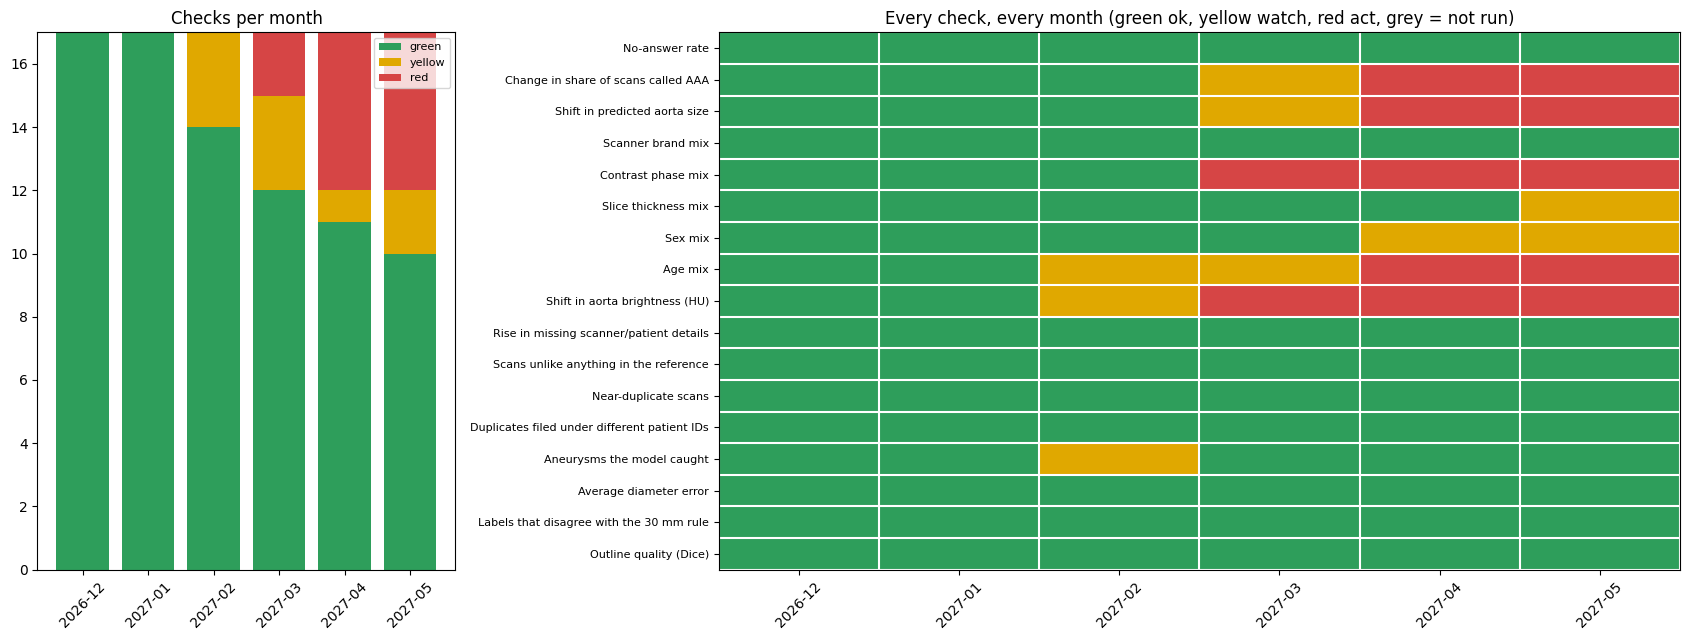

In [6]:
hist = pd.read_csv(OUT_DIR / "history.csv"); hist = hist[hist["hospital"] == HOSPITAL_NAME]
hist["month"] = hist["month"].astype(str)
months = sorted(hist["month"].unique())
trig_order = hist.drop_duplicates("trigger")["trigger"].tolist()

fig, ax = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1, 2.3]})
x = np.arange(len(summary)); w = 0.8
ax[0].bar(x, summary["green"], w, color="#2e9e5b", label="green")
ax[0].bar(x, summary["yellow"], w, bottom=summary["green"], color="#e0a800", label="yellow")
ax[0].bar(x, summary["red"], w, bottom=summary["green"] + summary["yellow"], color="#d64545", label="red")
ax[0].set_xticks(x); ax[0].set_xticklabels(summary["month"], rotation=45); ax[0].legend(fontsize=8); ax[0].set_title("Checks per month")

code_map = {"GREEN": 0, "YELLOW": 1, "RED": 2, "n/a": 3}
piv = hist.pivot(index="trigger", columns="month", values="status").reindex(trig_order)[months]
grid = piv.apply(lambda col: col.map(code_map)).fillna(3).to_numpy(float)
ax[1].imshow(grid, cmap=ListedColormap(["#2e9e5b", "#e0a800", "#d64545", "#d9d9d9"]), vmin=0, vmax=3, aspect="auto")
ax[1].set_xticks(range(len(months))); ax[1].set_xticklabels(months, rotation=45)
ax[1].set_yticks(range(len(trig_order))); ax[1].set_yticklabels(trig_order, fontsize=8)
ax[1].set_xticks(np.arange(-.5, len(months)), minor=True); ax[1].set_yticks(np.arange(-.5, len(trig_order)), minor=True)
ax[1].grid(which="minor", color="w", lw=1.5); ax[1].tick_params(which="minor", length=0)
ax[1].set_title("Every check, every month (green ok, yellow watch, red act, grey = not run)")
plt.tight_layout(); fig.savefig(OUT_DIR / f"{HOSPITAL_NAME}_dashboard.png", dpi=120, bbox_inches="tight"); plt.show()

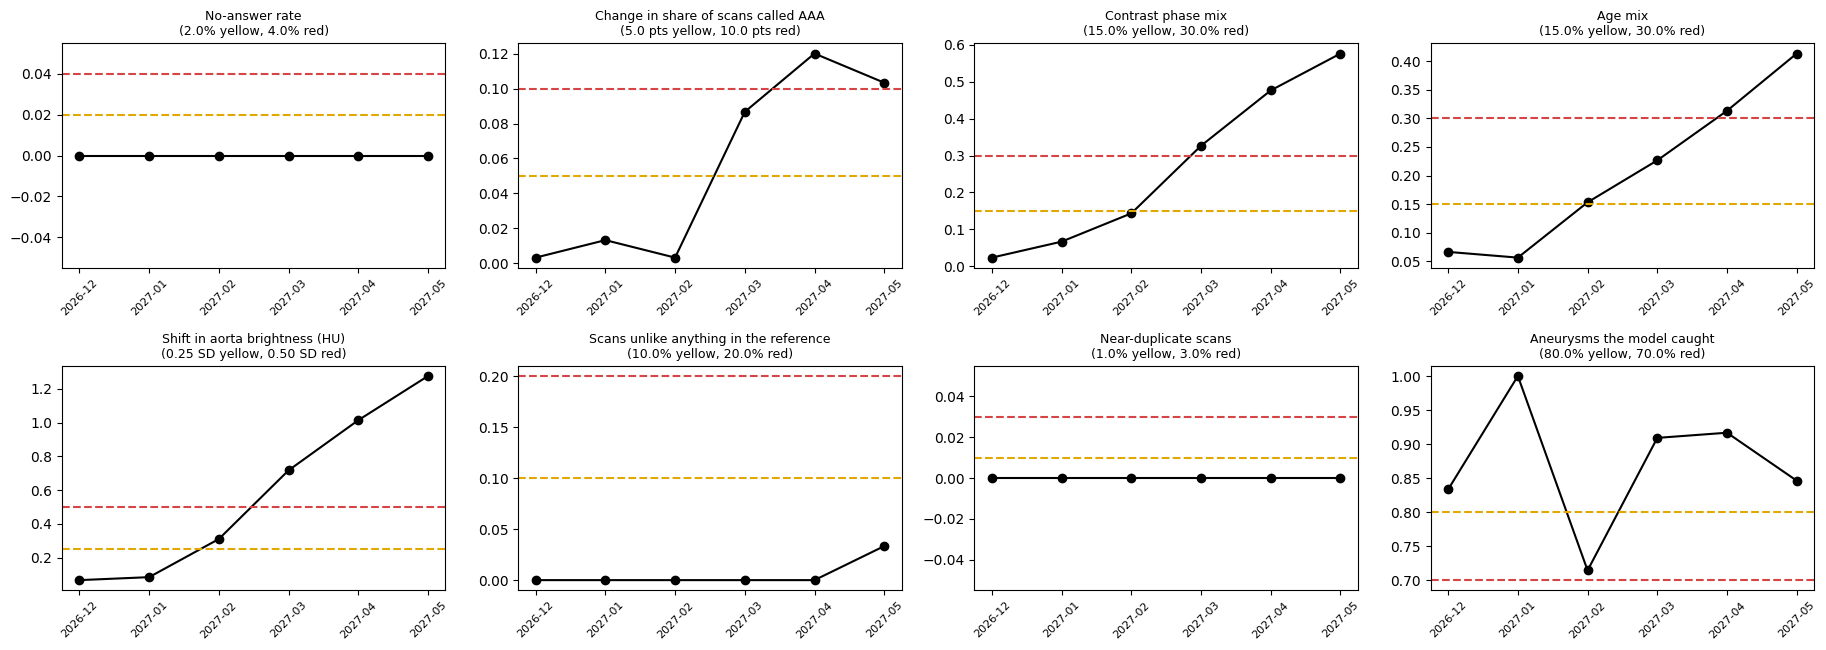

In [7]:
# the numbers behind the key warning signs, with the alert levels drawn in
watch = [t for t in ["No-answer rate", "Change in share of scans called AAA", "Contrast phase mix", "Age mix",
                     "Shift in aorta brightness (HU)", "Scans unlike anything in the reference",
                     "Near-duplicate scans", "Aneurysms the model caught"] if t in set(hist["trigger"])]
n = len(watch); ncols = 4; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.3 * nrows)); axes = np.atleast_1d(axes).ravel()
for ax_, t in zip(axes, watch):
    h = hist[hist["trigger"] == t].set_index("month").reindex(months)
    kind = hist.loc[hist["trigger"] == t, "kind"].iloc[0]; yl, rd = h["yellow"].dropna().iloc[0], h["red"].dropna().iloc[0]
    ax_.plot(months, h["value"], "o-", color="k"); ax_.axhline(yl, color="#e0a800", ls="--"); ax_.axhline(rd, color="#d64545", ls="--")
    ax_.set_title(f"{t}\n({monitor.fmt(yl, kind)} yellow, {monitor.fmt(rd, kind)} red)", fontsize=9); ax_.tick_params(axis="x", rotation=45, labelsize=8)
for ax_ in axes[n:]: ax_.axis("off")
plt.tight_layout(); fig.savefig(OUT_DIR / f"{HOSPITAL_NAME}_key_trends.png", dpi=120, bbox_inches="tight"); plt.show()

## 5. Hand-over files: index page and JSON summary

* `monitoring/index.html`: one page listing every month with its verdict and a link to that month's report.
* `monitoring/<hospital>_monthly_summary.json`: the same information for other software.

In [8]:
colors = {"Review needed": "#d64545", "Proceed with care": "#e0a800", "Comparable to validation": "#2e9e5b"}
trs = "".join(
    f'<tr><td><a href="report_{HOSPITAL_NAME}_{r["month"]}.html">{r["month"]}</a></td><td>{r["n_scans"]}</td>'
    f'<td style="background:{colors[r["verdict"]]};color:#fff;font-weight:bold">{r["verdict"]}</td>'
    f'<td>{r["red"]} red, {r["yellow"]} yellow</td><td>{r["red_triggers"] or "-"}</td></tr>' for _, r in summary.iterrows())
index_html = f"""<html><head><meta charset="utf-8"><style>body{{font-family:Helvetica,Arial,sans-serif;max-width:900px;margin:20px auto;font-size:13px}}
td,th{{padding:6px 8px;border-bottom:1px solid #eee;text-align:left}}</style></head><body>
<h2>AI aneurysm model: go-live monitoring for {HOSPITAL_NAME}</h2><p>Compared with the validation hospital {REFERENCE_NAME}. Click a month for its one-page report.</p>
<table><tr><th>Month</th><th>Scans</th><th>Verdict</th><th>Alerts</th><th>Red alerts</th></tr>{trs}</table>
<p><img src="{HOSPITAL_NAME}_dashboard.png" style="width:100%"></p></body></html>"""
(OUT_DIR / "index.html").write_text(index_html)

first_red = next((r["month"] for _, r in summary.iterrows() if r["red"]), None)
monthly_json = {"hospital": HOSPITAL_NAME, "reference": REFERENCE_NAME, "scenario": SCENARIO if SIMULATE else "real data",
                "first_month_with_a_red_alert": first_red, "history_file": str(OUT_DIR / "history.csv"),
                "months": [{**{k: (bool(v) if isinstance(v, (np.bool_, bool)) else (int(v) if isinstance(v, (np.integer,)) else v)) for k, v in r.items()},
                            "red_triggers": [t for t in r["red_triggers"].split(", ") if t], "yellow_triggers": [t for t in r["yellow_triggers"].split(", ") if t]}
                           for r in summary.to_dict("records")]}
(OUT_DIR / f"{HOSPITAL_NAME}_monthly_summary.json").write_text(json.dumps(monthly_json, indent=2))
print("first month with a red alert:", first_red)
print("saved:", OUT_DIR / "index.html", "and", OUT_DIR / f"{HOSPITAL_NAME}_monthly_summary.json")
display(HTML((OUT_DIR / f"report_{HOSPITAL_NAME}_{month_dirs[-1].name}.html").read_text()))

first month with a red alert: 2027-03
saved: monitoring/index.html and monitoring/demo_hospital_monthly_summary.json


## 6. A script for real use: `run_monthly.py`

Each month, once the hospital has dropped its files into `monthly_data/<hospital>/<YYYY-MM>/`, one command makes that month's report and updates the history. The script exits with code 2 when there is a red alert, so a scheduler (cron, Task Scheduler, GitHub Actions) can send an email or message.

In [9]:
SCRIPT = """# Monthly go-live check for the AAA model.
#
# usage (one line):
#   python run_monthly.py --hospital my_hospital --month 2027-01 --folder monthly_data/my_hospital/2027-01 --profile monitoring/reference_profile.joblib
#
# The folder holds features.parquet, predictions.parquet, embeddings.parquet and, when confirmed
# answers exist, labels.parquet. Exit code 2 = at least one RED alert (so a scheduler can notify someone).
import argparse, sys
from pathlib import Path
import joblib
import pandas as pd
import monitor


def read_month(folder):
    folder = Path(folder)
    df = (pd.read_parquet(folder / "features.parquet")
          .merge(pd.read_parquet(folder / "predictions.parquet"), on="case_id", how="left")
          .merge(pd.read_parquet(folder / "embeddings.parquet"), on="case_id"))
    if (folder / "labels.parquet").exists():
        df = df.merge(pd.read_parquet(folder / "labels.parquet"), on="case_id", how="left")
    return df


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--hospital", required=True)
    ap.add_argument("--month", required=True, help="e.g. 2027-01")
    ap.add_argument("--folder", required=True)
    ap.add_argument("--profile", default="monitoring/reference_profile.joblib")
    ap.add_argument("--out", default="monitoring")
    a = ap.parse_args()
    prof = joblib.load(a.profile)
    res = monitor.monthly_check(read_month(a.folder), prof, a.hospital, month=a.month, out_dir=a.out)
    c = res["status"].value_counts()
    red, yel = int(c.get("RED", 0)), int(c.get("YELLOW", 0))
    print(f"{a.hospital} {a.month}: {red} red, {yel} yellow, {int(c.get('GREEN', 0))} green")
    for _, r in res[res["status"].isin(["RED", "YELLOW"])].iterrows():
        print(f"  [{r['status']}] {r['trigger']}: {r['meaning']}")
    print("report:", Path(a.out) / f"report_{a.hospital}_{a.month}.html")
    sys.exit(2 if red else 0)


if __name__ == "__main__":
    main()
"""
Path("run_monthly.py").write_text(SCRIPT)
last = month_dirs[-1]
print("written run_monthly.py. Example for the latest month:\n")
print(f"python run_monthly.py --hospital {HOSPITAL_NAME} --month {last.name} --folder {last} --profile {OUT_DIR / 'reference_profile.joblib'}")

written run_monthly.py. Example for the latest month:

python run_monthly.py --hospital demo_hospital --month 2027-05 --folder monthly_data/demo_hospital/2027-05 --profile monitoring/reference_profile.joblib


## Using this with real monthly data

1. Keep `monitor.py`, `run_monthly.py` and `monitoring/reference_profile.joblib` together (re-create the profile with section 2 if the reference changes or you upgrade scikit-learn).
2. Each month the hospital drops four files into `monthly_data/<hospital>/<YYYY-MM>/` with the **same columns** as the practice hospitals. `labels.parquet` can be added later; re-run the month and the accuracy checks appear.
3. Run `python run_monthly.py ...` (or section 3 of this notebook with `SIMULATE = False`).
4. Open `monitoring/index.html`.

**Reading the reports.** Green = similar to the validation hospital. Yellow = look at it. Red = review before relying on the model. Alert levels are starting points to agree with the vendor and the clinical team. With a few dozen scans per month, and only a handful of aneurysms, single months are noisy: **look at the trend, not one point.**

**What this does not do yet:** it compares each month on its own, so a patient scanned in two different months is not detected as a repeat; and it does not send messages by itself (use the exit code of `run_monthly.py` for that).